In [ ]:
# Figure 2: Spatial pattern of test results

In [2]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np 

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib
import matplotlib.ticker as mticker
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


#import cmaps
from cmcrameri import cm 
import matplotlib as mpl
import matplotlib.pyplot as plt
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
from matplotlib.gridspec import GridSpec
import xarray as xr



from fast_o3_iv import metrics
from fast_o3_iv import utils as tools
from fast_o3_iv.config import PROCESSED_DATA_DIR


In [3]:
ds = xr.open_dataset(PROCESSED_DATA_DIR / "figure_data" / "Figure2_local_metrics_fields.nc")

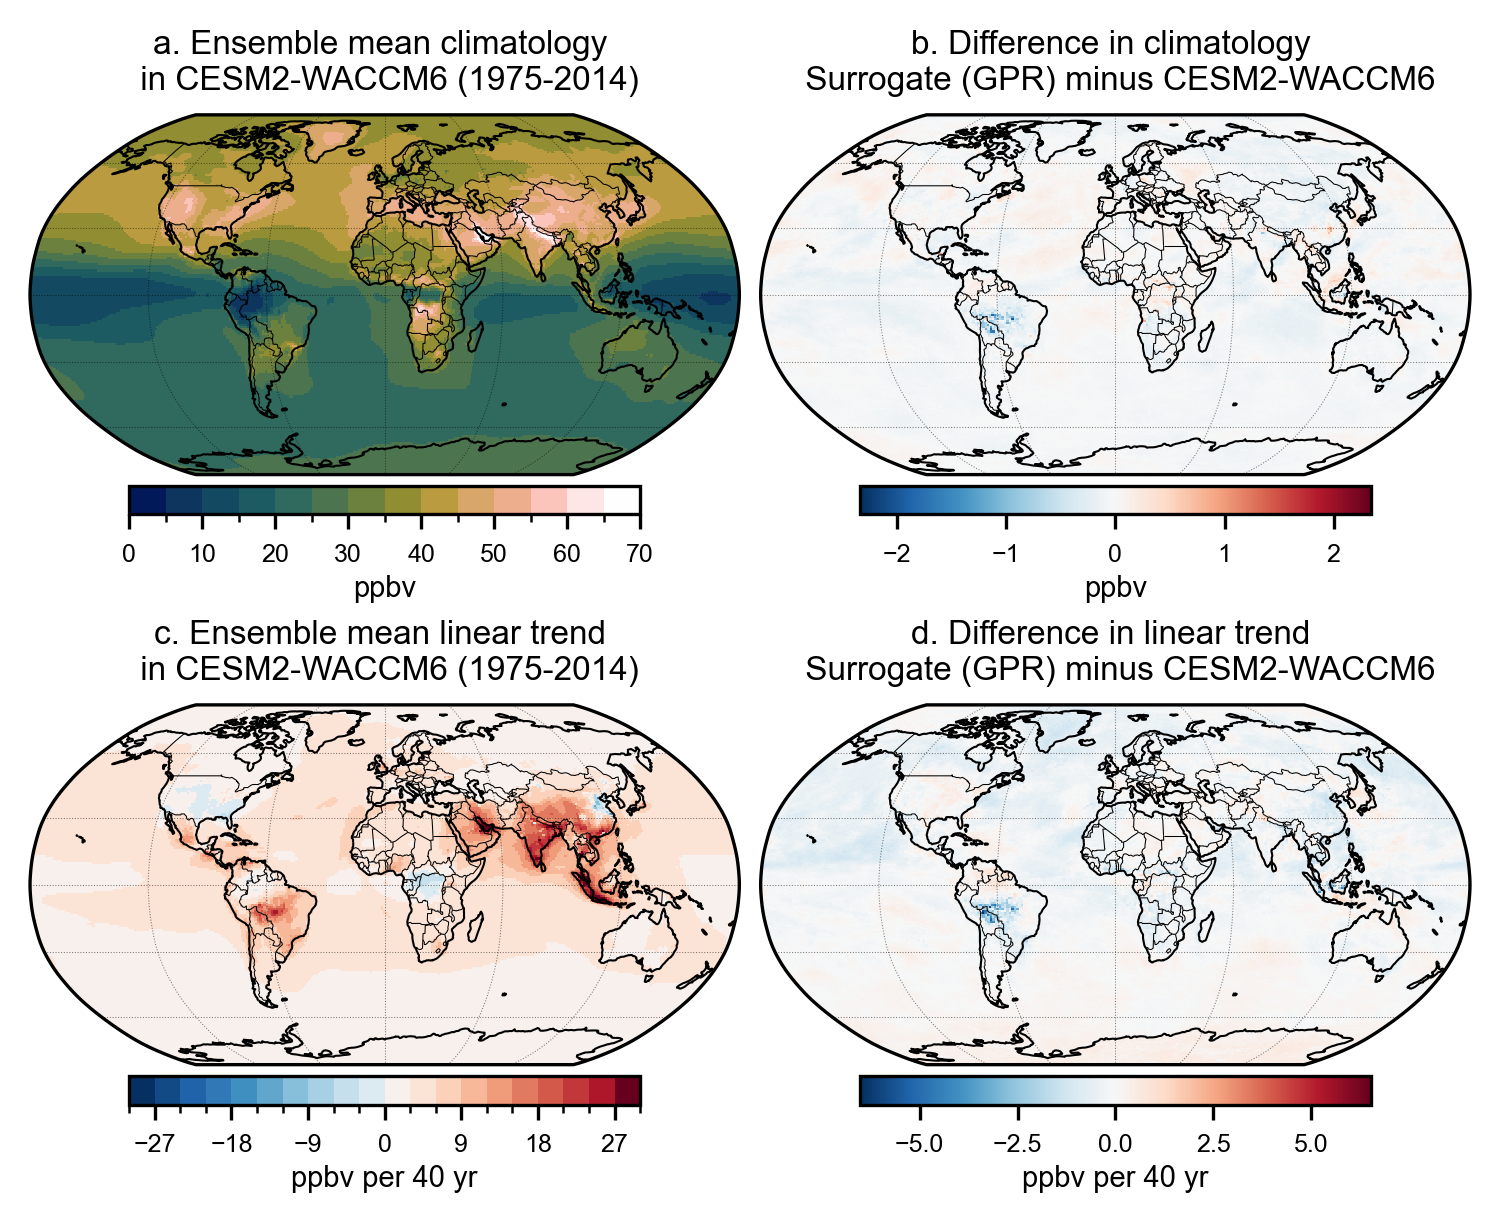

In [ ]:

tools.set_matplotlib_font("Arial")
lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter = LatitudeFormatter()
color = 'black'

mpl.rcParams.update({
    'axes.edgecolor': color,      
    'xtick.color': color,         
    'ytick.color': color,         
    'xtick.labelcolor': color,    
    'ytick.labelcolor': color,    
    'grid.color': color,          
    'axes.labelcolor': color,    
    'axes.titlecolor': color,    
})

mpl.rcParams.update({
    'font.size': 8, 
    'axes.titlesize': 10, 
    'axes.labelsize': 10,
    'xtick.labelsize': 8, 
    'ytick.labelsize': 8, 
    'legend.fontsize': 8,
    'figure.titlesize': 10
})

def style_map(ax):
    ax.set_global()
    ax.coastlines(linewidth=0.5, color="black")
    ax.add_feature(cfeature.BORDERS, linewidth=0.25, edgecolor="black")

    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=False,
        linewidth=0.25,
        color="black",
        alpha=0.5,
        linestyle=":"
    )
    gl.xformatter = lon_formatter
    gl.yformatter = lat_formatter
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
    return gl

def add_panel_cbar(fig, ax, mappable, label=None, y=-0.12):
    cax = inset_axes(
        ax,
        width="80%",
        height="8%",
        loc="lower center",
        bbox_to_anchor=(0.05, y, 0.90, 1.0),   # x0, y0, width, height)
        bbox_transform=ax.transAxes,
        borderpad=0.1
    )
    cb = fig.colorbar(mappable, cax=cax, orientation="horizontal")
    cb.ax.tick_params(labelsize=6)
    if label:
        cb.set_label(label, fontsize=7, labelpad=2) 
    return cb

fig_width_in = 6
fig_height_in = 4.8

fig = plt.figure(figsize=(fig_width_in, fig_height_in), dpi=300)

gs1 = GridSpec(2, 2, top=0.90, bottom=0.10, left=0.08, right=0.88,
               hspace=0.05, wspace=0.03)
               

proj = ccrs.Robinson(central_longitude=0)
ax1 = fig.add_subplot(gs1[0, 0], projection=proj)
ax2 = fig.add_subplot(gs1[0, 1], projection=proj)
ax3 = fig.add_subplot(gs1[1, 0], projection=proj)
ax4 = fig.add_subplot(gs1[1, 1], projection=proj)

axes = [ax1, ax2, ax3, ax4]
titles= ["a. Ensemble mean climatology \n in CESM2-WACCM6 (1975-2014)", 
         "b. Difference in climatology \n Surrogate (GPR) minus CESM2-WACCM6", 
         "c. Ensemble mean linear trend \n in CESM2-WACCM6 (1975-2014)", 
         "d. Difference in linear trend \n Surrogate (GPR) minus CESM2-WACCM6"]


for ax, t in zip([ax1, ax2, ax3, ax4], titles):
    ax.set_title(t, color="black", fontsize=8)
    style_map(ax)

#---------------# climatology #---------------#
vmax = 70
vmin = 0
step = 5
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1
base = cm.batlowW
colors = base(np.linspace(0, 1, n_bins))
cmap = matplotlib.colors.ListedColormap(colors)
norm = matplotlib.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

m1 = ds['clim_true'].plot.pcolormesh(
    ax=ax1, transform=ccrs.PlateCarree(),
    cmap=cmap, norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   

)
add_panel_cbar(fig, ax1, m1, label="ppbv")

#---------------# climatology diff #---------------#
m2 = ds['clim_diff'].plot.pcolormesh(
    ax=ax2, transform=ccrs.PlateCarree(),
    cmap="RdBu_r", #norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False, 

)
add_panel_cbar(fig, ax2, m2, label="ppbv")


#---------------# linear trend #---------------#
vmax = 30
vmin = -vmax
step = 3
levels = np.arange(vmin, vmax+step, step) 
cmap = plt.get_cmap('RdBu_r', len(levels)+1) 
norm = matplotlib.colors.BoundaryNorm(levels,  ncolors=cmap.N, clip=False)

m3 = ds['trend_true'].plot.pcolormesh(
    ax=ax3, transform=ccrs.PlateCarree(),
    cmap=cmap, norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # keeps  ax.set_title()
)
add_panel_cbar(fig, ax3, m3, label="ppbv per 40 yr")

#---------------# trend diff #---------------#

m4 = ds['trend_diff'].plot.pcolormesh(
    ax=ax4, transform=ccrs.PlateCarree(),
    cmap="RdBu_r", #norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()

)
add_panel_cbar(fig, ax4, m4, label="ppbv per 40 yr")

